# One Siamese network for all 4 classes
Second version of the Siamese model. Changes from the per class notebooks:

- one shared model for curl, healthy, slug and spot so the scores of the classes can be compared
- backbone features are averaged (global average pooling) and go through a learned 128 value embedding
- 224x224 images instead of 100x100
- new random pairs every epoch, the positive is always a different leaf
- a leaf is compared with all train images, not 10

**1. Imports**

In [1]:
import os
import glob
import random
import logging
import warnings
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
# hide the deprecation warnings (tensorflow resets the log level in jupyter)
logging.getLogger('tensorflow').addFilter(lambda record: record.levelno >= logging.ERROR)
warnings.filterwarnings('ignore')

import tensorflow as tf
from keras import layers, models
from keras.applications import MobileNetV2, EfficientNetB0

from split_data import CLASSES, leaf_id, pick_leaves

tf.random.set_seed(42)
random.seed(42)

**2. Settings**

Run `split_data.py` once before this so `King_Saud/Test` exists.

In [3]:
# On Colab mount Drive and use the Drive folder instead
# from google.colab import drive
# drive.mount('/gdrive')
# DATA_DIR = '/gdrive/My Drive/King_Saud'
DATA_DIR = 'King_Saud'
BACKBONE = 'EfficientNetB0'   # or 'MobileNetV2'
SIZE = 224

**3. Load images**

Every image is used once (the same file can be in more than one folder). The class is in the file name.

In [4]:
def list_images(split):
    files = {}
    for path in sorted(glob.glob(os.path.join(DATA_DIR, split, '*', '*', '*.jpg'))):
        files.setdefault(os.path.basename(path).replace('(1)', ''), path)
    names = sorted(files)
    return names, [files[n] for n in names]


def load_images(paths):
    images = np.zeros((len(paths), SIZE, SIZE, 3), dtype='uint8')
    for i, path in enumerate(paths):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        images[i] = tf.cast(tf.round(tf.image.resize(img, (SIZE, SIZE))), tf.uint8)
    return images


train_names, train_paths = list_images('Train')
test_names, test_paths = list_images('Test')
train_images = load_images(train_paths)
test_images = load_images(test_paths)

train_labels = np.array([CLASSES.index(n.split('_')[0]) for n in train_names])
test_labels = np.array([CLASSES.index(n.split('_')[0]) for n in test_names])
train_leaf = [leaf_id(n) for n in train_names]

for i, cls in enumerate(CLASSES):
    print('{:8s} train {:4d}  test {:4d}'.format(cls, np.sum(train_labels == i), np.sum(test_labels == i)))

curl     train  387  test   99
healthy  train  313  test   84
slug     train  400  test  100
spot     train  413  test  103


In [5]:
# 20% of the train leaves for validation (picking the number of epochs)
val_leaves = pick_leaves(train_names, seed=1)
val_idx = [i for i in range(len(train_names)) if train_leaf[i] in val_leaves]
fit_idx = [i for i in range(len(train_names)) if train_leaf[i] not in val_leaves]
print('fit images:', len(fit_idx), ' val images:', len(val_idx))

fit images: 1205  val images: 308


**4. Backbone features**

The backbone is frozen at first, so its features are computed once.

In [6]:
def make_backbone():
    if BACKBONE == 'MobileNetV2':
        base = MobileNetV2(weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3))
        # MobileNetV2 wants pixels between -1 and 1
        scale = layers.Rescaling(1 / 127.5, offset=-1)
    else:
        base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(SIZE, SIZE, 3))
        # EfficientNetB0 rescales the pixels itself
        scale = layers.Rescaling(1.0)
    return base, scale


base, scale = make_backbone()
pool = layers.GlobalAveragePooling2D()

def features(images):
    out = []
    for i in range(0, len(images), 64):
        x = scale(images[i:i+64].astype('float32'))
        out.append(pool(base(x, training=False)).numpy())
    return np.concatenate(out)

train_feats = features(train_images)
test_feats = features(test_images)
train_feats.shape

(1513, 1280)

**5. Siamese head**

Both images go through the same embedding layer. The absolute difference of the two embeddings goes to a Dense layer with one sigmoid output (1 = same class).

In [7]:
class L1Dist(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, input_embedding, validation_embedding):
        return tf.math.abs(input_embedding - validation_embedding)


embedding = layers.Dense(128, name='embedding')
head = layers.Dense(1, activation='sigmoid', name='head')

feat_a = layers.Input(shape=(train_feats.shape[1],))
feat_b = layers.Input(shape=(train_feats.shape[1],))
head_model = models.Model([feat_a, feat_b], head(L1Dist(name='distance')(embedding(feat_a), embedding(feat_b))))
head_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')

In [8]:
def sample_pairs(idx, n_pairs):
    # half same class (different leaf), half other class
    by_class = {c: [i for i in idx if train_labels[i] == c] for c in range(len(CLASSES))}
    a, b, y = [], [], []
    for _ in range(n_pairs // 2):
        c = random.randrange(len(CLASSES))
        anchor = random.choice(by_class[c])
        positive = random.choice(by_class[c])
        while train_leaf[positive] == train_leaf[anchor]:
            positive = random.choice(by_class[c])
        other = random.choice([k for k in range(len(CLASSES)) if k != c])
        negative = random.choice(by_class[other])
        a += [anchor, anchor]
        b += [positive, negative]
        y += [1.0, 0.0]
    return np.array(a), np.array(b), np.array(y)


def classify(query_emb, ref_emb, ref_labels):
    # average score against every reference image of each class, highest class wins
    w, b = head.get_weights()
    scores = np.zeros((len(query_emb), len(CLASSES)))
    for c in range(len(CLASSES)):
        refs = ref_emb[ref_labels == c]
        for i, q in enumerate(query_emb):
            s = 1 / (1 + np.exp(-(np.abs(refs - q) @ w[:, 0] + b[0])))
            scores[i, c] = s.mean()
    return scores


def val_accuracy(fit_emb, val_emb):
    pred = np.argmax(classify(val_emb, fit_emb, train_labels[fit_idx]), axis=1)
    return np.mean(pred == train_labels[val_idx])

**6. Train the head (backbone frozen)**

40 epochs of 4000 new pairs, the weights of the epoch with the best validation accuracy are kept.

In [9]:
best_acc, best_weights = 0, None
for epoch in range(1, 41):
    a, b, y = sample_pairs(fit_idx, 4000)
    hist = head_model.fit([train_feats[a], train_feats[b]], y, batch_size=32, epochs=1, verbose=0)

    emb = embedding(train_feats).numpy()
    acc = val_accuracy(emb[fit_idx], emb[val_idx])
    print('Epoch {:2d}  loss: {:.4f}  val accuracy: {:.4f}'.format(epoch, hist.history['loss'][0], acc))
    if acc > best_acc:
        best_acc, best_weights, best_epoch = acc, head_model.get_weights(), epoch

head_model.set_weights(best_weights)
print('best epoch', best_epoch, 'val accuracy {:.4f}'.format(best_acc))

Epoch  1  loss: 0.4212  val accuracy: 0.8571


Epoch  2  loss: 0.2738  val accuracy: 0.8669


Epoch  3  loss: 0.2237  val accuracy: 0.8604


Epoch  4  loss: 0.1737  val accuracy: 0.8636


Epoch  5  loss: 0.1551  val accuracy: 0.8734


Epoch  6  loss: 0.1589  val accuracy: 0.8604


... (30 outputs left out)

Epoch 37  loss: 0.0330  val accuracy: 0.8571


Epoch 38  loss: 0.0315  val accuracy: 0.8474


Epoch 39  loss: 0.0230  val accuracy: 0.8409


Epoch 40  loss: 0.0254  val accuracy: 0.8409
best epoch 5 val accuracy 0.8734


**7. Full model**

Backbone, pooling and the trained embedding together, so it works on images.

In [10]:
def make_embed_model(augment):
    inp = layers.Input(shape=(SIZE, SIZE, 3))
    x = inp
    if augment:
        x = layers.RandomFlip('horizontal_and_vertical')(x)
        x = layers.RandomRotation(0.2)(x)
        x = layers.RandomBrightness(0.2, value_range=(0, 255))(x)
    x = base(scale(x), training=False)
    return models.Model(inp, embedding(pool(x)), name='embed')


embed_model = make_embed_model(augment=False)
img_a = layers.Input(shape=(SIZE, SIZE, 3), name='input_img')
img_b = layers.Input(shape=(SIZE, SIZE, 3), name='validation_img')
siamese_model = models.Model([img_a, img_b], head(L1Dist(name='distance')(embed_model(img_a), embed_model(img_b))),
                             name='SiameseNetwork')

def embed_images(images):
    return embed_model.predict(images, batch_size=64, verbose=0)

**8. Test on the held out leaves**

Every test image is compared with all train images.

In [11]:
train_emb = embed_images(train_images)
test_emb = embed_images(test_images)
test_pred = np.argmax(classify(test_emb, train_emb, train_labels), axis=1)

print('Test accuracy: {:.4f}'.format(np.mean(test_pred == test_labels)))
print()
print('rows = true class, columns = predicted')
print(' ' * 9 + ''.join('{:>9s}'.format(c) for c in CLASSES))
for i, cls in enumerate(CLASSES):
    row = [np.sum((test_labels == i) & (test_pred == j)) for j in range(len(CLASSES))]
    print('{:9s}'.format(cls) + ''.join('{:9d}'.format(v) for v in row))

Test accuracy: 0.9456

rows = true class, columns = predicted
              curl  healthy     slug     spot
curl            99        0        0        0
healthy          0       84        0        0
slug             0        0       88       12
spot             0        6        3       94


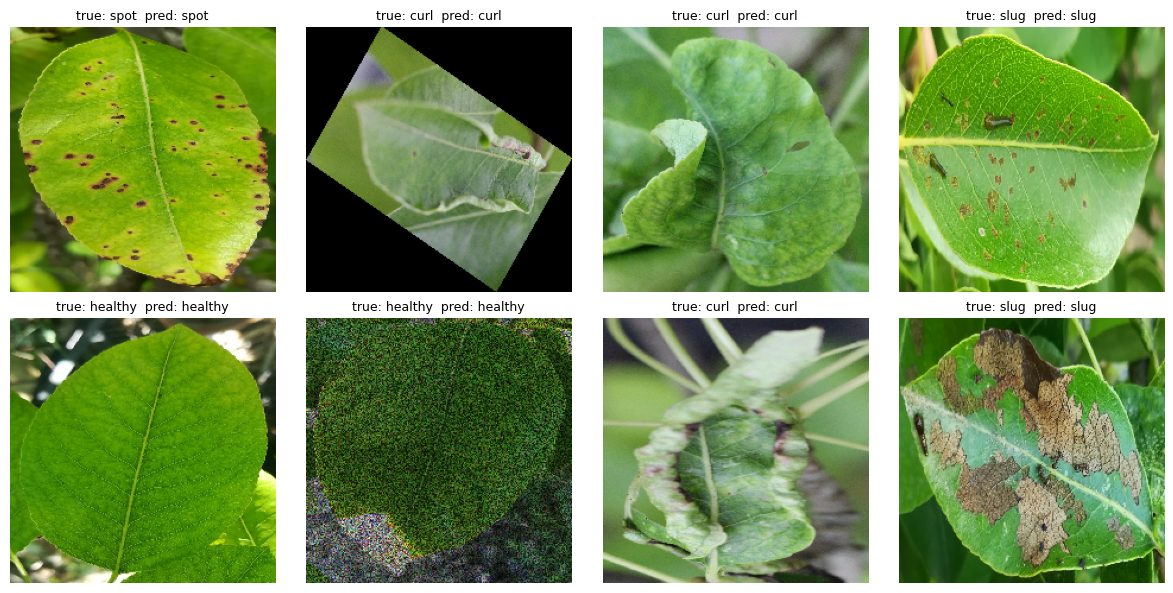

In [12]:
# a few test leaves with the prediction
rng = np.random.default_rng(0)
pick = rng.choice(len(test_images), 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, pick):
    ax.imshow(test_images[i])
    ax.set_title('true: {}  pred: {}'.format(CLASSES[test_labels[i]], CLASSES[test_pred[i]]), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**9. Save**

The model and the embeddings of the train images (predict.py compares new leaves with them).

In [13]:
os.makedirs('models', exist_ok=True)
siamese_model.save('models/siamese_{}.h5'.format(BACKBONE))
np.savez('models/refs_{}.npz'.format(BACKBONE), embeddings=train_emb, labels=train_labels)

In [14]:
# check the saved model loads back and gives the same embeddings
loaded = tf.keras.models.load_model('models/siamese_{}.h5'.format(BACKBONE),
                                    custom_objects={'L1Dist': L1Dist}, compile=False)
np.abs(loaded.get_layer('embed').predict(test_images[:4], verbose=0) - test_emb[:4]).max()

0.0